## 1. 머신러닝 개요

### 1-1 머신러닝이란?

> 기계(컴퓨터 알고리즘)가 스스로 데이터를 학습하여, 서로 다른 변수 간의 관계를 찾아 나가는 과정
>

**해결하려는 문제에 따른 분류**

| 알고리즘 | 해결하는 문제 | 교재 예시 |
| --- | --- | --- |
| 예측(prediction) | 값을 예측 | 주가, 환율 등 경제지표 예측 |
| 분류(classification) | 어느 범주에 속하는지 판별 | 은행에서 고객을 분류해 대출 승인/거절 |
| 군집(clustering) | 비슷한 대상끼리 묶기 | 비슷한 소비패턴을 가진 고객 유형을 군집으로 묶기 |

### 1-2 지도 학습 vs 비지도 학습

| 구분 | 지도 학습 | 비지도 학습 |
| --- | --- | --- |
| 정의 | 데이터를 다른 데이터와 함께 컴퓨터 알고리즘에 입력하는 방식 | 정답 데이터 없이 컴퓨터 알고리즘 스스로 데이터로부터 패턴을 찾아내는 방식 |
| 알고리즘(분석모형) |   • 회귀분석
  • 분류 |   • 군집 분석 |
| 특징 |   • 정답을 알고 있는 상태에서 학습
  • 모형 평가 방법이 다양한 편 |   • 정답이 없는 상태에서 서로 비슷한 데이터를 찾아서 그룹화
  • 모형 평가 방법이 제한적 |

### 1-3 머신러닝 프로세스

1. 데이터를 알고리즘이 이해할 수 있는 형태로 변환
- 수집한 관측값을 속성 기준으로 정리
- 이를 위해 판다스 데이터프레임을 사용
    - 데이터프레임의 열 = 속성(변수)
    - 데이터프레임의 행 = 하나의 관측값
    - 관측값의 개수만큼 행을 늘리면 됨
2. 모형 학습과 평가에 쓰는 데이터의 구분
- 훈련 데이터: 속성 간의 관계를 분석해 결과를 예측하는 모형을 학습하는 데 사용
- 검증 데이터: 학습을 마치 모형의 예측 능력 평가에 사용
3. 머신 러닝 프로세스

!image.png

## 2. 회귀분석

> 가격, 매출, 주가, 환율, 수량처럼 연속적인 값을 갖는 연속 변수를 예측하는 데 주로 쓰는 알고리즘, 지도학습에 속함
>
- 종속 변수(예측 변수): 분석 모형이 예측하고자 하는 목표
- 독립 변수(설명 변수): 예측을 위해 모형이 사용하는 속성

### 2-1 단순회귀분석

> 두 변수 사이의 일대일대응, 즉 확률적 통계적 상관성을 찾는 알고리즘
>
- $y=ax+b$
    
    →알고리즘은 훈련 데이터를 반복 학습해 a,b를 찾는다
#### 2-1-1 Step 1 데이터 준비

- `pd.set_option("옵션이름", 값)`: pandas 출력 방식을 설정하는 함수
    - `“display.max.columns”` : 출력할 열의 최대 개수

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

'''
[Step 1] 데이터 준비 - read_csv() 함수로 자동차 연비 데이터셋 가져오기
'''
# CSV 파일을 데이터프레임으로 변환

# 구글 드라이브 마운트 (최초 1회 인증 진행)
from google.colab import drive
drive.mount('/content/drive')

# 데이터셋 가져오기
file_path = '/content/drive/MyDrive/학회/part 7 data/auto-mpg.csv'
df = pd.read_csv(file_path,header=None)

# 열 이름 지정
df.columns = ['mpg','cylinders','displacement','horsepower','weight',
              'acceleration','model year','origin','name']

# 데이터 살펴보기
print(df.head())
print('\n')

# IPython 디스플레이 설정 - 출력할 열의 개수 한도 늘리기
pd.set_option('display.max_columns', 10)
print(df.head())

Mounted at /content/drive
    mpg  cylinders  displacement horsepower  weight  acceleration  model year  \
0  18.0          8         307.0      130.0  3504.0          12.0          70   
1  15.0          8         350.0      165.0  3693.0          11.5          70   
2  18.0          8         318.0      150.0  3436.0          11.0          70   
3  16.0          8         304.0      150.0  3433.0          12.0          70   
4  17.0          8         302.0      140.0  3449.0          10.5          70   

   origin                       name  
0       1  chevrolet chevelle malibu  
1       1          buick skylark 320  
2       1         plymouth satellite  
3       1              amc rebel sst  
4       1                ford torino  


    mpg  cylinders  displacement horsepower  weight  acceleration  model year  \
0  18.0          8         307.0      130.0  3504.0          12.0          70   
1  15.0          8         350.0      165.0  3693.0          11.5          70   
2  18.0 

#### 2-1-2 Step 2 데이터 탐색

In [2]:
'''
[Step 2] 데이터 탐색
'''

# 데이터 자료형 확인
print(df.info())
print('\n')

# 데이터 통계 요약정보 확인
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    object 
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   name          398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB
None


              mpg   cylinders  displacement       weight  acceleration  \
count  398.000000  398.000000    398.000000   398.000000    398.000000   
mean    23.514573    5.454774    193.425879  2970.424623     15.568090   
std      7.815984    1.701004    104.269838   846.841774      2.757689   
min      9.000000    3.000000     68.000000  1613.000000 

In [3]:
# horsepower 열의 자료형 변경(문자열 -> 숫자)
print(df['horsepower'].unique())    # horsepower 열의 고유값 확인
print('\n')

df['horsepower'].replace('?', np.nan, inplace=True)       # '?'을 np.nan으로 변경
df.dropna(subset=['horsepower'], axis=0, inplace=True)    # 누락 데이터 행 삭제
df['horsepower'] = df['horsepower'].astype('float')       # 문자열을 실수형으로 변환

print(df.describe())

['130.0' '165.0' '150.0' '140.0' '198.0' '220.0' '215.0' '225.0' '190.0'
 '170.0' '160.0' '95.00' '97.00' '85.00' '88.00' '46.00' '87.00' '90.00'
 '113.0' '200.0' '210.0' '193.0' '?' '100.0' '105.0' '175.0' '153.0'
 '180.0' '110.0' '72.00' '86.00' '70.00' '76.00' '65.00' '69.00' '60.00'
 '80.00' '54.00' '208.0' '155.0' '112.0' '92.00' '145.0' '137.0' '158.0'
 '167.0' '94.00' '107.0' '230.0' '49.00' '75.00' '91.00' '122.0' '67.00'
 '83.00' '78.00' '52.00' '61.00' '93.00' '148.0' '129.0' '96.00' '71.00'
 '98.00' '115.0' '53.00' '81.00' '79.00' '120.0' '152.0' '102.0' '108.0'
 '68.00' '58.00' '149.0' '89.00' '63.00' '48.00' '66.00' '139.0' '103.0'
 '125.0' '133.0' '138.0' '135.0' '142.0' '77.00' '62.00' '132.0' '84.00'
 '64.00' '74.00' '116.0' '82.00']


              mpg   cylinders  displacement  horsepower       weight  \
count  392.000000  392.000000    392.000000  392.000000   392.000000   
mean    23.445918    5.471939    194.411990  104.469388  2977.584184   
std      7.805007    1

/tmp/ipykernel_1513/3825576681.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['horsepower'].replace('?', np.nan, inplace=True)       # '?'을 np.nan으로 변경


#### 2-1-3 Step 3 속성 선택

- `데이터프레임.plot(kind="scatter", x="열이름", y="열이름", c="색", s=점크기, figsize=(가로, 세로))`: x, y 열로 산점도를 그리는 메소
- `sns.regplot(x="열이름", y="열이름", data=데이터프레임, ax=축, fit_reg=True/False)`: 산점도와 회귀선을 함께 그리는 함수
    - `fit_reg=False`: 회귀선을 그리지 않음
- `sns.jointplot(x="열이름", y="열이름", data=데이터프레임, kind="reg")`: 산점도와 각 변수의 히스토그램을 함께 그리는 함수
    - `kind=”reg”` : 회귀선 표시
- `sns.pairplot(데이터프레임)`: 열을 두 개씩 짝지은 모든 경우의 산점도를 그리는 함수
    - 자기 자신과의 관계는 히스토그램으로 표시

In [4]:
'''
[Step 3] 속성(feature 또는 variable) 선택
'''

# 분석에 활용할 열(속성) 선택(연비, 실린더, 출력, 중량)
ndf = df[['mpg', 'cylinders', 'horsepower', 'weight']]
print(ndf.head())

    mpg  cylinders  horsepower  weight
0  18.0          8       130.0  3504.0
1  15.0          8       165.0  3693.0
2  18.0          8       150.0  3436.0
3  16.0          8       150.0  3433.0
4  17.0          8       140.0  3449.0


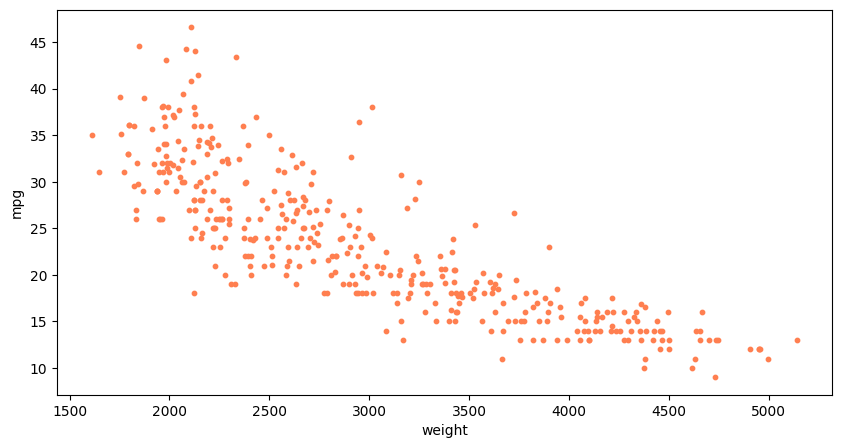

In [5]:
### 종속 변수 Y인 "연비(mpg)"와 다른 변수 간의 선형관계를 그래프(산점도)로 확인
# Matplotlib으로 산점도 그리기
ndf.plot(kind='scatter', x='weight', y='mpg',  c='coral', s=10, figsize=(10, 5))
plt.show()
plt.close()

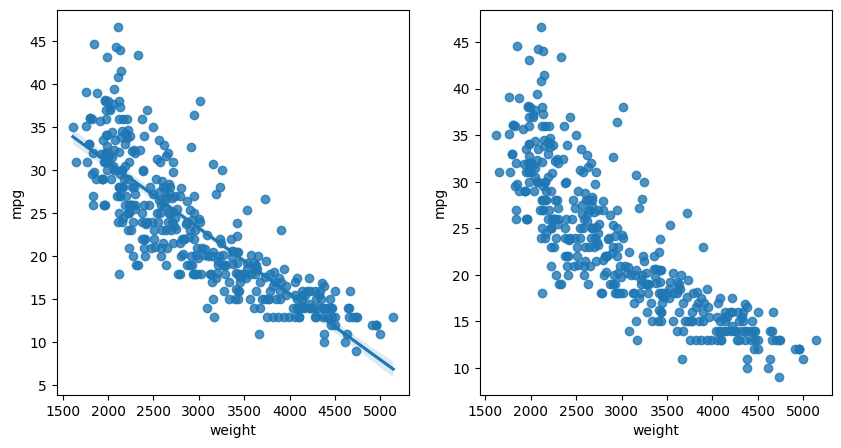

In [6]:
# seaborn으로 산점도 그리기
fig = plt.figure(figsize=(10, 5))
ax1 = fig.add_subplot(1, 2, 1)
ax2 = fig.add_subplot(1, 2, 2)
sns.regplot(x='weight', y='mpg', data=ndf, ax=ax1)                  # 회귀선 표시
sns.regplot(x='weight', y='mpg', data=ndf, ax=ax2, fit_reg=False)   # 회귀선 미표시
plt.show()
plt.close()

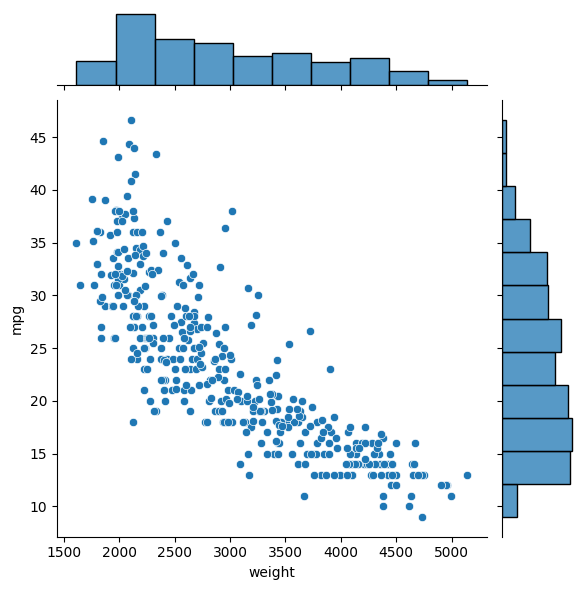

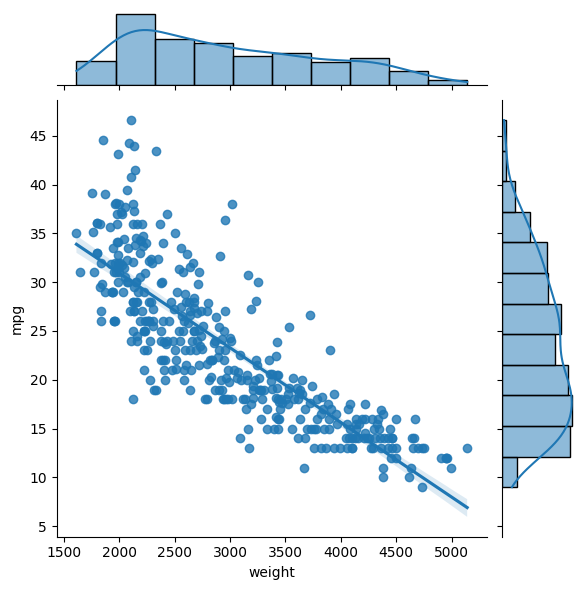

In [7]:
# seaborn 조인트 그래프 - 산점도, 히스토그램
sns.jointplot(x='weight', y='mpg', data=ndf)                # 회귀선 없음
sns.jointplot(x='weight', y='mpg', kind='reg', data=ndf)    # 회귀선 표시
plt.show()
plt.close()

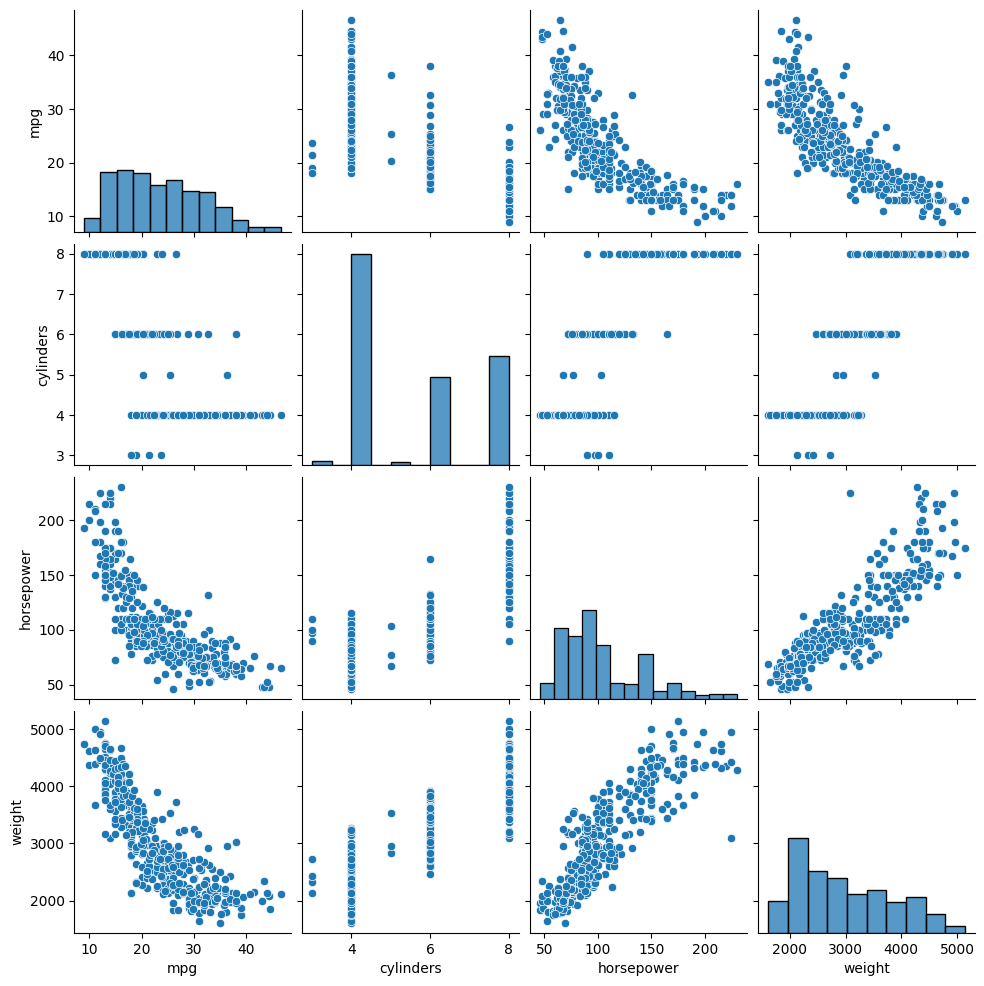

In [8]:
# seaborn pariplot으로 두 변수 간의 모든 경우의 수 그리기
grid_ndf = sns.pairplot(ndf)
plt.show()
plt.close()

#### 2-1-4 Step 4 훈련/검증 데이터 분할

- `from 패키지.모듈 import 이름`: 지정한 모듈에서 특정 이름(함수, 클래스 등)만 현재 코드로 불러오는 import 문
- `sklearn` : scikit-learn 패키지의 import 이름
    - 머신러닝 알고리즘과 도구를 모아 둔 라이브러리
- `model_selection`: sklearn 안에서 데이터 분할, 교차 검증, 하이퍼파라미터 탐색 등 모형 선택과 관련된 기능을 모아 둔 하위 모듈
- `X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=비율, random_state=정수)` : 독립 변수 X와 종속 변수 y를 훈련용과 검증용으로 무작위로 분할해서 반환하는 함수
    - x: 독립 변수 데이터, 2차원
    - y: 종속 변수 데이터, 1차원
    - `test_size=비율` : 검증 데이터가 차지할 비율
    - `random_state=정수` : 무작위 추출의 기본값
        - 같은 값을 주면 매번 같은 같은 방식으로 분할됨
        - 생략하면 실행할 때마다 분할이 달라짐
    - 반환 순서: `x_train` →`x_test` →`y_train` →`y_test`

In [9]:
'''
[Step 4] 데이터셋 구분 - 훈련용(train data)/검증용(test data)
'''

# 속성(변수) 선택
X=ndf[['weight']]  # 독립 변수 X
y=ndf['mpg']       # 종속 변수 Y

# train data와 test data로 구분(7:3 비율)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,                  # 독립 변수
                                                    y,                  # 종속 변수
                                                    test_size=0.3,      # 검증 30%
                                                    random_state=10)    # 랜덤 추출 값

print('train data 개수: ', len(X_train))
print('test data 개수: ', len(X_test))

train data 개수:  274
test data 개수:  118


#### 2-1-5 Step5 모형 학습 및 검증

- `LinearRegression()`: 선형회귀분석 모형 객체를 생성하는 함수
- `모형객체.fit(X_train, y_train)`: 훈련 데이터로 모형을 학습시키는 메소드
- `모형객체.score(X_test, y_test)`: 검증 데이터로 모형의 결정계수(R²) 를 계산해 반환하는 메소드
    - 값이 클수록 예측 능력이 좋다고 판단
- `모형객체.coef_`: 학습된 독립 변수의 계수(기울기)
- `모형객체.intercept_`: 학습된 상수항(y절편)
- `모형객체.predict(X)`: 독립 변수 X를 입력받아 모형이 계산한 예측값을 반환하는 메소드

In [10]:
'''
[Step 5] 단순회귀분석 모형 만들기 - sklearn 사용
'''

# sklearn 라이브러리에서 선형회귀분석 모듈 가져오기
from sklearn.linear_model import LinearRegression

# 단순회귀분석 모형 객체 생성
lr = LinearRegression()

# train data를 가지고 모형 학습
lr.fit(X_train, y_train)

# 학습을 마친 모형에 test data를 적용하여 결정계수(R-제곱) 계산
r_square = lr.score(X_test, y_test)
print(r_square)

0.6822458558299322


In [11]:
# 회귀식의 기울기
print('기울기 a: ', lr.coef_)
print('\n')

# 회귀식의 y절편
print('y절편 b', lr.intercept_)

기울기 a:  [-0.00775343]


y절편 b 46.7103662572801


/tmp/ipykernel_1513/515537655.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  ax1 = sns.distplot(y, hist=False, label="y")
/tmp/ipykernel_1513/515537655.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  ax2 = sns.distplot(y_hat, hist=False, label="y_hat", ax=ax1)


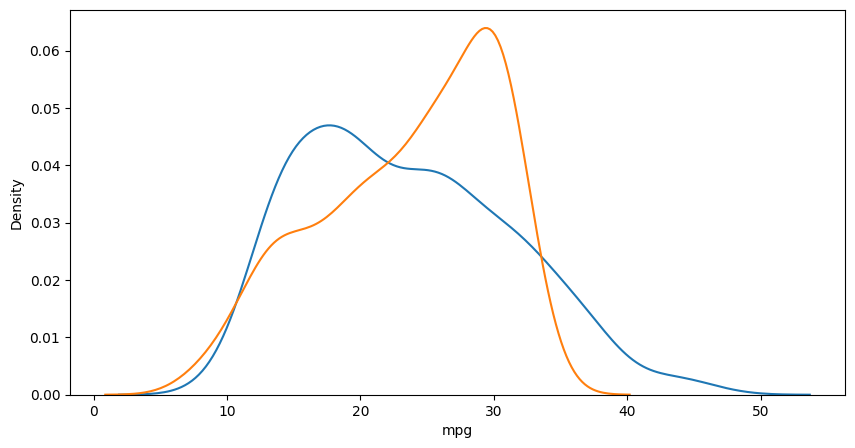

In [12]:
# 모형에 전체 X 데이터를 입력하여 예측한 값 y_hat을 실제 값 y와 비교
y_hat = lr.predict(X)

plt.figure(figsize=(10, 5))
ax1 = sns.distplot(y, hist=False, label="y")
ax2 = sns.distplot(y_hat, hist=False, label="y_hat", ax=ax1)
plt.show()
plt.close()

### 2-2 다항회귀분석

- 2차 이상의 다항 함수를 이용해 두 변수 간의 관계를 설명
- 2차 함수: $y=ax^2+bx+c$로 표시, 학습을 통해 3개의 계수를 찾음

#### 2-2-1 데이터 준비

In [13]:
# -*- coding: utf-8 -*-

### 기본 라이브러리 불러오기
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

'''
[Step 1-4] 데이터 준비
'''

# CSV 파일을 데이터프레임으로 변환
# 구글 드라이브 마운트 (최초 1회 인증 진행)
from google.colab import drive
drive.mount('/content/drive')

# 데이터셋 가져오기
file_path = '/content/drive/MyDrive/학회/part 7 data/auto-mpg.csv'
df = pd.read_csv(file_path,header=None)

# 열 이름 지정
df.columns = ['mpg','cylinders','displacement','horsepower','weight',
              'acceleration','model year','origin','name']

# horsepower 열의 자료형 변경(문자열 -> 숫자)
df['horsepower'].replace('?', np.nan, inplace=True)       # '?'을 np.nan으로 변경
df.dropna(subset=['horsepower'], axis=0, inplace=True)    # 누락 데이터 행 삭제
df['horsepower'] = df['horsepower'].astype('float')       # 문자열을 실수형으로 변환

# 분석에 활용할 열(속성) 선택(연비, 실린더, 출력, 중량)
ndf = df[['mpg', 'cylinders', 'horsepower', 'weight']]

# ndf 데이터를 train data와 test data로 구분(7:3 비율)
X=ndf[['weight']]  # 독립 변수 X
y=ndf['mpg']       # 종속 변수 Y

# train data와 test data로 구분(7:3 비율)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=10)

print('훈련 데이터: ', X_train.shape)
print('검증 데이터: ', X_test.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
훈련 데이터:  (274, 1)
검증 데이터:  (118, 1)


/tmp/ipykernel_1513/695269153.py:27: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['horsepower'].replace('?', np.nan, inplace=True)       # '?'을 np.nan으로 변경


#### 2-2-2 모형 학습 및 검증

- `PolynomialFeatures(degree=차수)`: 입력 데이터를 다항식 형태로 변환하는 변환기 객체를 생성하는 함수
- `변환기객체.fit_transform(X)`: 데이터 X에 맞춰 변환 방식을 학습한 뒤 바로 변환해 반환하는 메소드

In [14]:
'''
[Step 5] 비선형회귀분석 모형 - sklearn 사용
'''

# sklearn 라이브러리에서 필요한 모듈 가져오기
from sklearn.linear_model import LinearRegression         # 선형회귀분석
from sklearn.preprocessing import PolynomialFeatures      # 다항식 변환

# 다항식 변환
poly = PolynomialFeatures(degree=2)           # 2차항 적용
X_train_poly=poly.fit_transform(X_train)      # X_train 데이터를 2차항으로 변형

print('원 데이터: ', X_train.shape)
print('2차항 변환 데이터: ', X_train_poly.shape)

원 데이터:  (274, 1)
2차항 변환 데이터:  (274, 3)


In [15]:
# train data를 가지고 모형 학습
pr = LinearRegression()
pr.fit(X_train_poly, y_train)

# 학습을 마친 모형에 test data를 적용하여 결정계수(R-제곱) 계산
X_test_poly = poly.fit_transform(X_test)      # X_test 데이터를 2차항으로 변형
r_square = pr.score(X_test_poly,y_test)
print(r_square)

0.708700926297548


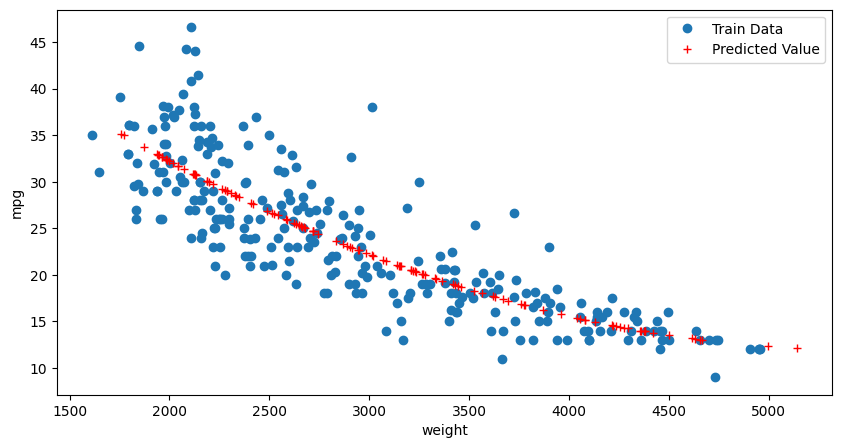

In [16]:
# train data의 산점도와 test data로 예측한 회귀선을 그래프로 출력
y_hat_test = pr.predict(X_test_poly)

fig = plt.figure(figsize=(10, 5))
ax = fig.add_subplot(1, 1, 1)
ax.plot(X_train, y_train, 'o', label='Train Data')         # 데이터 분포
ax.plot(X_test, y_hat_test, 'r+', label='Predicted Value') # 모형이 학습한 회귀선
ax.legend(loc='best')
plt.xlabel('weight')
plt.ylabel('mpg')
plt.show()
plt.close()

/tmp/ipykernel_1513/3301306182.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  ax1 = sns.distplot(y, hist=False, label="y")
/tmp/ipykernel_1513/3301306182.py:7: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  ax2 = sns.distplot(y_hat, hist=False, label="y_hat", ax=ax1)


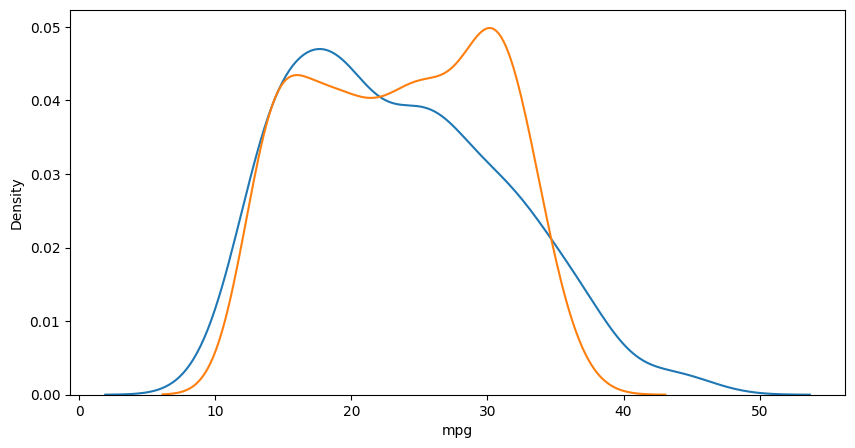

In [17]:
# 모형에 전체 X 데이터를 입력하여 예측한 값 y_hat을 실제 값 y와 비교
X_ploy = poly.fit_transform(X)
y_hat = pr.predict(X_ploy)

plt.figure(figsize=(10, 5))
ax1 = sns.distplot(y, hist=False, label="y")
ax2 = sns.distplot(y_hat, hist=False, label="y_hat", ax=ax1)
plt.show()
plt.close()

## 3. 분류

> 예측하려는 대상의 속성을 입력받아 목표 변수가 가진 카테고리 값 중 하나로 분류해 예측하는 알고리즘
>
- 지도학습에 속함

### 3-1 KNN

> k-Nearest-Neighbors의 약칭, k개의 가까운 이웃이라는 뜻
>
1. 새로운 관측값이 주어지면 기존 데이터 중에서 가장 속성이 비슷한 k개의 이웃을 먼저 찾음
2. 가까운 이웃들이 갖고 있는 목표 값과 같은 값으로 분류해 예측
- k값에 따라 예측 결과가 달라짐 →적절한 k값을 찾는 것이 중요
#### 3-1-1 Step 1 데이터 준비

In [18]:
# -*- coding: utf-8 -*-

### 기본 라이브러리 불러오기
import pandas as pd
import seaborn as sns

'''
[Step 1] 데이터 준비 - Seaborn에서 제공하는 titanic 데이터셋 가져오기
'''

# load_dataset 함수를 사용하여 데이터프레임으로 변환
df = sns.load_dataset('titanic')

# 데이터 살펴보기
print(df.head())
print('\n')

# IPython 디스플레이 설정 - 출력할 열의 개수 한도 늘리기
pd.set_option('display.max_columns', 15)
print(df.head())

   survived  pclass     sex   age  sibsp  ...  adult_male  deck  embark_town  \
0         0       3    male  22.0      1  ...        True   NaN  Southampton   
1         1       1  female  38.0      1  ...       False     C    Cherbourg   
2         1       3  female  26.0      0  ...       False   NaN  Southampton   
3         1       1  female  35.0      1  ...       False     C  Southampton   
4         0       3    male  35.0      0  ...        True   NaN  Southampton   

  alive  alone  
0    no  False  
1   yes  False  
2   yes   True  
3   yes  False  
4    no   True  

[5 rows x 15 columns]


   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0 

#### 3-1-2 Step 2 데이터 탐색

- `데이터프레임.columns.values`: 열 이름을 배열로 반환
- `데이터프레임.dropna(subset=[열이름], how="any", axis=0)`: `subset`에 지정한 열에 NaN이 있는 행을 삭제
    - `how=”any”`: 지정한 열 중 하나라도 NaN이면 삭제
    - `how=”all”`: 모두 NaN일 때 삭제

In [19]:
'''
[Step 2] 데이터 탐색/전처리
'''

# 데이터 자료형 확인
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB
None


In [20]:
# NaN값이 많은 deck 열 삭제, embarked와 내용이 겹치는 embark_town 열 삭제
rdf = df.drop(['deck', 'embark_town'], axis=1)
print(rdf.columns.values)

['survived' 'pclass' 'sex' 'age' 'sibsp' 'parch' 'fare' 'embarked' 'class'
 'who' 'adult_male' 'alive' 'alone']


In [21]:
# age 열에 나이 데이터가 없는 모든 행 삭제 - age 열(891개 중 177개의 NaN값)
rdf = rdf.dropna(subset=['age'], how='any', axis=0)
print(len(rdf))

714


In [22]:
# embarked 열의 NaN값을 승선도시 중에서 가장 많이 출현한 값으로 치환하기
most_freq = rdf['embarked'].value_counts(dropna=True).idxmax()
print(most_freq)
print('\n')

print(rdf.describe(include='all'))
print('\n')

rdf['embarked'].fillna(most_freq, inplace=True)

S


          survived      pclass   sex         age       sibsp       parch  \
count   714.000000  714.000000   714  714.000000  714.000000  714.000000   
unique         NaN         NaN     2         NaN         NaN         NaN   
top            NaN         NaN  male         NaN         NaN         NaN   
freq           NaN         NaN   453         NaN         NaN         NaN   
mean      0.406162    2.236695   NaN   29.699118    0.512605    0.431373   
std       0.491460    0.838250   NaN   14.526497    0.929783    0.853289   
min       0.000000    1.000000   NaN    0.420000    0.000000    0.000000   
25%       0.000000    1.000000   NaN   20.125000    0.000000    0.000000   
50%       0.000000    2.000000   NaN   28.000000    0.000000    0.000000   
75%       1.000000    3.000000   NaN   38.000000    1.000000    1.000000   
max       1.000000    3.000000   NaN   80.000000    5.000000    6.000000   

              fare embarked  class  who adult_male alive alone  
count   714.000000

/tmp/ipykernel_1513/3346919161.py:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  rdf['embarked'].fillna(most_freq, inplace=True)


#### 3-1-3 Step 3 속성 선택

- `pd.get_dummies(시리즈, prefix="접두어")`: 범주형 데이터를 더미 변수 로 변환
    - 고유값마다 열이 하나씩 만들어짐
        - 해당 값이면 1, 아니면 0이 들어감
    - `prefix`: 새 열 이름 앞에 접두어가 붙음
- `pd.concat([데이터프레임1, 데이터프레임2], axis=1)`: 데이터프레임을 연결
    - `axis=1`: 열 방향으로 이어 붙임

In [23]:
'''
[Step 3] 분석에 사용할 속성 선택
'''

# 분석에 활용할 열(속성) 선택
ndf = rdf[['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'embarked']]
print(ndf.head())

   survived  pclass     sex   age  sibsp  parch embarked
0         0       3    male  22.0      1      0        S
1         1       1  female  38.0      1      0        C
2         1       3  female  26.0      0      0        S
3         1       1  female  35.0      1      0        S
4         0       3    male  35.0      0      0        S


In [24]:
# 원핫인코딩 - 범주형 데이터를 모형이 인식할 수 있도록 숫자형으로 변환
onehot_sex = pd.get_dummies(ndf['sex'])
ndf = pd.concat([ndf, onehot_sex], axis=1)

# prefix='town'으로 열 이름 앞에 town이 붙음
onehot_embarked = pd.get_dummies(ndf['embarked'], prefix='town')
ndf = pd.concat([ndf, onehot_embarked], axis=1)

ndf.drop(['sex', 'embarked'], axis=1, inplace=True)
print(ndf.head())

   survived  pclass   age  sibsp  parch  female   male  town_C  town_Q  town_S
0         0       3  22.0      1      0   False   True   False   False    True
1         1       1  38.0      1      0    True  False    True   False   False
2         1       3  26.0      0      0    True  False   False   False    True
3         1       1  35.0      1      0    True  False   False   False    True
4         0       3  35.0      0      0   False   True   False   False    True


#### 3-1-4 Step 4 훈련/검증 데이터 분할

- `preprocessing.StandardScaler().fit(X).transform(X)` : 각 열을 평균 0, 표준편차 1이 되도록 변환
    - `StandardScaler()`: 변환기 객체를 생성
    - `.fit(X)` : X의 열별 평균과 표준편차를 계산
    - `.transform(X)` : 계산된 값으로 X를 변환해 배열로 반환

In [25]:
'''
[Step 4] 데이터셋 구분 - 훈련용(train data)/검증용(test data)
'''

# 속성(변수) 선택
X=ndf[['pclass', 'age', 'sibsp', 'parch', 'female', 'male',
       'town_C', 'town_Q', 'town_S']]  # 설명 변수 X
y=ndf['survived']                      # 예측 변수 Y

# 설명 변수 데이터를 정규화(normalization)
from sklearn import preprocessing
X = preprocessing.StandardScaler().fit(X).transform(X)

# train data와 test data로 구분(7:3 비율)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=10)

print('train data 개수: ', X_train.shape)
print('test data 개수: ', X_test.shape)

train data 개수:  (499, 9)
test data 개수:  (215, 9)


#### 3-1-5 Step 5 모형 학습 및 검증

- `KNeighborsClassifier(n_neighbors=k)`: KNN 분류 모형 객체를 생성하는 함수
- `모형객체.fit(X_train, y_train)`: 훈련 데이터로 모형을 학습
- `모형객체.predict(X_test)`: 검증 데이터의 X를 입력받아 모형이 분류한 예측값 배열을 반환
- `시리즈.values`: 시리즈의 값을 넘파이 배열로 반환
- `metrics.confusion_matrix(y_test, y_hat)`: 실제 값과 예측값으로 Confusion Matrix를 계산해 2차원 배열로 반환
- `metrics.classification_report(y_test, y_hat)`: 클래스별 precision, recall, f1-score, support를 문자열 표로 반환

In [26]:
'''
[Step 5] KNN 분류 모형 - sklearn 사용
'''

# sklearn 라이브러리에서 KNN 분류 모형 가져오기
from sklearn.neighbors import KNeighborsClassifier

# 모형 객체 생성(k=5로 설정)
knn = KNeighborsClassifier(n_neighbors=5)

# train data를 가지고 모형 학습
knn.fit(X_train, y_train)

# test data를 가지고 y_hat을 예측(분류)
y_hat = knn.predict(X_test)

print(y_hat[0:10])
print(y_test.values[0:10])

[0 0 1 0 0 1 1 1 0 0]
[0 0 1 0 0 1 1 1 0 0]


In [27]:
# 모형 성능 평가 - Confusion Matrix 계산
from sklearn import metrics
knn_matrix = metrics.confusion_matrix(y_test, y_hat)
print(knn_matrix)

# 모형 성능 평가 - 평가 지표 계산
knn_report = metrics.classification_report(y_test, y_hat)
print(knn_report)

[[111  14]
 [ 24  66]]
              precision    recall  f1-score   support

           0       0.82      0.89      0.85       125
           1       0.82      0.73      0.78        90

    accuracy                           0.82       215
   macro avg       0.82      0.81      0.82       215
weighted avg       0.82      0.82      0.82       215



### 3-2 SVM support vector machine

- 벡터 개념 사용
- 데이터프레임의 각 열은 열 벡터로 구현됨
    - 열 벡터들이 각각 고유의 축을 갖는 벡터 공간을 만듦
    - 개별 관측값은 모든 속성에 대한 값을 해당 축의 좌표로 표시해 벡터 공간에서의 위치를 나타냄
- 훈련 데이터의 좌표와 정답을 입력받아 학습
    - 같은 분류 값을 찾는 데이터끼리 같은 공간에 위치하도록 벡터 공간을 여러 조각으로 나누는 경계를 찾음

#### 3-2-1 데이터 준비

In [28]:
# -*- coding: utf-8 -*-

### 기본 라이브러리 불러오기
import pandas as pd
import seaborn as sns

'''
[Step 1] 데이터 준비/기본 설정
'''

# load_dataset 함수를 사용하여 데이터프레임으로 변환
df = sns.load_dataset('titanic')

# IPython 디스플레이 설정 - 출력할 열의 개수 한도 늘리기
pd.set_option('display.max_columns', 15)

'''
[Step 2] 데이터 탐색/전처리
'''

# NaN값이 많은 deck 열 삭제, embarked와 내용이 겹치는 embark_town 열 삭제
rdf = df.drop(['deck', 'embark_town'], axis=1)

# age 열에 나이 데이터가 없는 모든 행 삭제 - age 열(891개 중 177개의 NaN값)
rdf = rdf.dropna(subset=['age'], how='any', axis=0)

# embarked 열의 NaN값을 승선도시 중에서 가장 많이 출현한 값으로 치환하기
most_freq = rdf['embarked'].value_counts(dropna=True).idxmax()
rdf['embarked'].fillna(most_freq, inplace=True)

'''
[Step 3] 분석에 사용할 속성 선택
'''

# 분석에 활용할 열(속성) 선택
ndf = rdf[['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'embarked']]

# 원핫인코딩 - 범주형 데이터를 모형이 인식할 수 있도록 숫자형으로 변환
onehot_sex = pd.get_dummies(ndf['sex'])
ndf = pd.concat([ndf, onehot_sex], axis=1)

onehot_embarked = pd.get_dummies(ndf['embarked'], prefix='town')
ndf = pd.concat([ndf, onehot_embarked], axis=1)

ndf.drop(['sex', 'embarked'], axis=1, inplace=True)

'''
[Step 4] 데이터셋 구분 - 훈련용(train data)/검증용(test data)
'''

# 속성(변수) 선택
X=ndf[['pclass', 'age', 'sibsp', 'parch', 'female', 'male',
       'town_C', 'town_Q', 'town_S']]  # 독립 변수 X
y=ndf['survived']                      # 종속 변수 Y

# 설명 변수 데이터를 정규화(normalization)
from sklearn import preprocessing
X = preprocessing.StandardScaler().fit(X).transform(X)

# train data와 test data로 구분(7:3 비율)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=10)

print('train data 개수: ', X_train.shape)
print('test data 개수: ', X_test.shape)

train data 개수:  (499, 9)
test data 개수:  (215, 9)


/tmp/ipykernel_1513/3386338320.py:29: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  rdf['embarked'].fillna(most_freq, inplace=True)


#### 3-2-2 모형 학습 및 검증

- `svm.SVC(kernel="커널이름")`: SVM 분류 모형 객체를 생성하는 함수
- 커널(kernel): 데이터를 벡터 공간으로 매핑하는 함수
    - `kernel=”rbf”` 옵션: RBF 함수 적용

In [29]:
'''
[Step 5] SVM 분류 모형 - sklearn 사용
'''

# sklearn 라이브러리에서 SVM 분류 모형 가져오기
from sklearn import svm

# 모형 객체 생성(kernel='rbf' 적용)
svm_model = svm.SVC(kernel='rbf')

# train data를 가지고 모형 학습
svm_model.fit(X_train, y_train)

# test data를 가지고 y_hat 예측(분류)
y_hat = svm_model.predict(X_test)

print(y_hat[0:10])
print(y_test.values[0:10])

[0 0 1 0 0 0 1 0 0 0]
[0 0 1 0 0 1 1 1 0 0]


In [30]:
# 모형 성능 평가 - Confusion Matrix 계산
from sklearn import metrics
svm_matrix = metrics.confusion_matrix(y_test, y_hat)
print(svm_matrix)
print('\n')

# 모형 성능 평가 - 평가 지표 계산
svm_report = metrics.classification_report(y_test, y_hat)
print(svm_report)

[[120   5]
 [ 35  55]]


              precision    recall  f1-score   support

           0       0.77      0.96      0.86       125
           1       0.92      0.61      0.73        90

    accuracy                           0.81       215
   macro avg       0.85      0.79      0.80       215
weighted avg       0.83      0.81      0.81       215



### 3-3 Decision Tree

> 의사결정 나무, 트리 구조 사용
>
- 각 분기점에는 분석 대상의 속성들이 위치
    - 분기점마다 목표 값을 가장 잘 분류할 수 있는 속성을 찾아 배치
    - 그 속성 값을 이용해 새로운 가지를 만듦
- 최적의 속성 선택: 그 속성으로 분류한 값들이 구분된느 정도를 측정
    - Entropy를 주로 활용
        - Entropy: 다른 종류의 값들이 섞여 있는 정도를 나타냄
    - Entropy 낮을수록 분류가 잘 된 것임
    - Entropy가 일정 수준 이하로 낮아질 때까지 반복

#### 3-3-1 데이터 준비

In [31]:
# -*- coding: utf-8 -*-

### 기본 라이브러리 불러오기
import pandas as pd
import numpy as np

'''
[Step 1] 데이터 준비/기본 설정
'''

# Breast Cancer 데이터셋 가져오기(출처: UCI ML Repository)
uci_path = 'https://archive.ics.uci.edu/ml/machine-learning-databases/\
breast-cancer-wisconsin/breast-cancer-wisconsin.data'
df = pd.read_csv(uci_path, header=None)

# 열 이름 지정
df.columns = ['id','clump','cell_size','cell_shape', 'adhesion','epithlial',
              'bare_nuclei','chromatin','normal_nucleoli', 'mitoses', 'class']

# IPython 디스플레이 설정 - 출력할 열의 개수 한도 늘리기
pd.set_option('display.max_columns', 15)

In [32]:
'''
[Step 2] 데이터 탐색
'''

# 데이터 살펴보기
print(df.head())
print('\n')

# 데이터 자료형 확인
print(df.info())
print('\n')

# 데이터 통계 요약 정보 확인
print(df.describe())

        id  clump  cell_size  cell_shape  adhesion  epithlial bare_nuclei  \
0  1000025      5          1           1         1          2           1   
1  1002945      5          4           4         5          7          10   
2  1015425      3          1           1         1          2           2   
3  1016277      6          8           8         1          3           4   
4  1017023      4          1           1         3          2           1   

   chromatin  normal_nucleoli  mitoses  class  
0          3                1        1      2  
1          3                2        1      2  
2          3                1        1      2  
3          3                7        1      2  
4          3                1        1      2  


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699 entries, 0 to 698
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   id               699 non-null    int64 
 1   cl

In [33]:
# bare_nuclei 열의 자료형 변경(문자열 -> 숫자)
print(df['bare_nuclei'].unique())                          # bare_nuclei 열의 고유값 확인
print('\n')

df['bare_nuclei'].replace('?', np.nan, inplace=True)       # '?'을 np.nan으로 변경
df.dropna(subset=['bare_nuclei'], axis=0, inplace=True)    # 누락 데이터 행 삭제
df['bare_nuclei'] = df['bare_nuclei'].astype('int')        # 문자열을 정수형으로 변환

print(df.describe())                                       # 데이터 통계 요약 정보 확인

['1' '10' '2' '4' '3' '9' '7' '?' '5' '8' '6']


                 id       clump   cell_size  cell_shape    adhesion  \
count  6.830000e+02  683.000000  683.000000  683.000000  683.000000   
mean   1.076720e+06    4.442167    3.150805    3.215227    2.830161   
std    6.206440e+05    2.820761    3.065145    2.988581    2.864562   
min    6.337500e+04    1.000000    1.000000    1.000000    1.000000   
25%    8.776170e+05    2.000000    1.000000    1.000000    1.000000   
50%    1.171795e+06    4.000000    1.000000    1.000000    1.000000   
75%    1.238705e+06    6.000000    5.000000    5.000000    4.000000   
max    1.345435e+07   10.000000   10.000000   10.000000   10.000000   

        epithlial  bare_nuclei   chromatin  normal_nucleoli     mitoses  \
count  683.000000   683.000000  683.000000       683.000000  683.000000   
mean     3.234261     3.544656    3.445095         2.869693    1.603221   
std      2.223085     3.643857    2.449697         3.052666    1.732674   
min      1.

/tmp/ipykernel_1513/388380523.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['bare_nuclei'].replace('?', np.nan, inplace=True)       # '?'을 np.nan으로 변경


In [34]:
'''
[Step 3] 데이터셋 구분 - 훈련용(train data)/검증용(test data)
'''

# 속성(변수) 선택
X=df[['clump','cell_size','cell_shape', 'adhesion','epithlial',
      'bare_nuclei','chromatin','normal_nucleoli', 'mitoses']]     # 설명 변수 X
y=df['class']                                                      # 예측 변수 Y

# 설명 변수 데이터 정규화
from sklearn import preprocessing
X = preprocessing.StandardScaler().fit(X).transform(X)

# train data와 test data로 구분(7:3 비율)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=10)

print('train data 개수: ', X_train.shape)
print('test data 개수: ', X_test.shape)

train data 개수:  (478, 9)
test data 개수:  (205, 9)


#### 3-3-2 모형 학습 및 검증

- `tree.DecisionTreeClassifier(criterion="분류기준", max_depth=정수)`: Decision Tree 분류 모형 객체를 생성하는 함수
    - `criterion`: 각 분기점에서 최적의 속성을 찾기 위해 분류 정도를 평가하는 기준
    - `max_depth`: 트리 레벨의 최대치, 몇 단계까지 가지를 확장할지
- 라벨이 많아질수록 훈련 데이터에 대한 예측은 정확해짐
    
    ↔모형이 훈련 데이터에만 지나치게 최적화되어 실제 데이터 예측 능력은 떨어질 수 있음

In [35]:
'''
[Step 4] Decision Tree 분류 모형 - sklearn 사용
'''

# sklearn 라이브러리에서 Decision Tree 분류 모형 가져오기
from sklearn import tree

# 모형 객체 생성(criterion='entropy' 적용)
tree_model = tree.DecisionTreeClassifier(criterion='entropy', max_depth=5)

# train data를 가지고 모형 학습
tree_model.fit(X_train, y_train)

# test data를 가지고 y_hat 예측(분류)
y_hat = tree_model.predict(X_test)         # 2: benign(양성), 4: malignant(악성)

print(y_hat[0:10])
print(y_test.values[0:10])

[4 4 4 4 4 4 2 2 4 4]
[4 4 4 4 4 4 2 2 4 4]


In [36]:
# 모형 성능 평가 - Confusion Matrix 계산
from sklearn import metrics
tree_matrix = metrics.confusion_matrix(y_test, y_hat)
print(tree_matrix)
print('\n')

# 모형 성능 평가 - 평가 지표 계산
tree_report = metrics.classification_report(y_test, y_hat)
print(tree_report)

[[127   4]
 [  2  72]]


              precision    recall  f1-score   support

           2       0.98      0.97      0.98       131
           4       0.95      0.97      0.96        74

    accuracy                           0.97       205
   macro avg       0.97      0.97      0.97       205
weighted avg       0.97      0.97      0.97       205



## 4. 군집

> 군집 분석: 데이터셋의 관측값이 갖고 있는 여러 속성을 분석해 서로 비슷한 특징을 갖는 같은 클로스터로 묶는 알고리즘
>
- 다른 클러스터끼리는 서로 완전히 구분되는 특징을 가지므로 어느 클러스터에도 속하지 못하는 관측값이 있을 수 있음
- 비지도 학습

### 4-1 K-means

- 데이터 간 유사성을 측정하는 기준으로 각 클러스터의 중심까지의 거리를 이용
- 벡터 공간에 있는 데이터에 대해 k개의 클러스터가 주어졌을 때 클러스터 중심까지 거리가 가장 가까운 클러스터로 그 데이터를 할당
- 다른 클러스터끼리는 서로 완전히 구분되도록 일정한 거리 이상 떨어져야함
- k가 클수록 정확도 개선
    
    ↔너무 커지면 선택지가 너무 많아 분석의 효과가 사라짐
    

#### 4-1-1 데이터 준비

In [37]:
# -*- coding: utf-8 -*-

### 기본 라이브러리 불러오기
import pandas as pd
import matplotlib.pyplot as plt

'''
[Step 1] 데이터 준비
'''

# Wholesale customers 데이터셋 가져오기(출처: UCI ML Repository)
uci_path = 'https://archive.ics.uci.edu/ml/machine-learning-databases/\
00292/Wholesale%20customers%20data.csv'
df = pd.read_csv(uci_path, header=0)

'''
[Step 2] 데이터 탐색
'''

# 데이터 살펴보기
print(df.head())
print('\n')

# 데이터 자료형 확인
print(df.info())
print('\n')

# 데이터 통계 요약정보 확인
print(df.describe())

   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0        2       3  12669  9656     7561     214              2674        1338
1        2       3   7057  9810     9568    1762              3293        1776
2        2       3   6353  8808     7684    2405              3516        7844
3        1       3  13265  1196     4221    6404               507        1788
4        2       3  22615  5410     7198    3915              1777        5185


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen

In [38]:
'''
[Step 3] 데이터 전처리
'''

# 분석에 사용할 속성 선택
X = df.iloc[:, :]
print(X[:5])
print('\n')

# 설명 변수 데이터 정규화
from sklearn import preprocessing
X = preprocessing.StandardScaler().fit(X).transform(X)

print(X[:5])

   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0        2       3  12669  9656     7561     214              2674        1338
1        2       3   7057  9810     9568    1762              3293        1776
2        2       3   6353  8808     7684    2405              3516        7844
3        1       3  13265  1196     4221    6404               507        1788
4        2       3  22615  5410     7198    3915              1777        5185


[[ 1.44865163  0.59066829  0.05293319  0.52356777 -0.04111489 -0.58936716
  -0.04356873 -0.06633906]
 [ 1.44865163  0.59066829 -0.39130197  0.54445767  0.17031835 -0.27013618
   0.08640684  0.08915105]
 [ 1.44865163  0.59066829 -0.44702926  0.40853771 -0.0281571  -0.13753572
   0.13323164  2.24329255]
 [-0.69029709  0.59066829  0.10011141 -0.62401993 -0.3929769   0.6871443
  -0.49858822  0.09341105]
 [ 1.44865163  0.59066829  0.84023948 -0.05239645 -0.07935618  0.17385884
  -0.23191782  1.29934689]]


#### 4-1-2 모형 학습 및 검증

- `cluster.KMeans(init="초기화방식", n_clusters=k, n_init=정수)`: k-Means 군집 모형 객체를 생성
    - `n_clusters`: 만들 클러스터의 개수 k
    - `init=”k-means++”`: 처음 중심점을 정하는 방식, 중심점을 서로 멀리 떨어지게 고르는 방식
    - `n_init`: 서로 다른 초기 중심점으로 알고리즘을 반복 실행하는 횟수
- `모형객체.fit(X)`: 비지도 학습이라 X만 입력
- `모형객체.labels_`: 학습이 끝난 뒤 각 관측값이 할당된 클러스터 번호를 담은 배열
- `~불리언시리즈`: 참/거짓을 반전(NOT)

In [39]:
'''
[Step 4] k-means 군집 모형 - sklearn 사용
'''

# sklearn 라이브러리에서 cluster 군집 모형 가져오기
from sklearn import cluster

# 모형 객체 생성
kmeans = cluster.KMeans(init='k-means++', n_clusters=5, n_init=10)

# 모형 학습
kmeans.fit(X)

# 예측(군집)
cluster_label = kmeans.labels_
print(cluster_label)
print('\n')

# 예측 결과를 데이터프레임에 추가
df['Cluster'] = cluster_label
print(df.head())

[0 0 0 4 0 0 0 0 4 0 0 0 0 0 0 4 0 4 0 4 0 4 4 3 0 0 4 4 0 4 4 4 4 4 4 0 4
 0 0 4 4 4 0 0 0 0 0 3 0 0 4 4 0 0 4 4 3 0 4 4 0 3 0 0 4 3 4 0 4 4 4 4 4 0
 0 4 4 0 4 4 4 0 0 4 0 3 3 4 4 4 4 4 3 4 0 4 0 4 4 4 0 0 0 4 4 4 0 0 0 0 4
 0 4 4 4 4 4 4 4 4 4 4 4 0 4 4 4 0 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 0 4 4
 4 4 4 4 4 4 4 0 0 4 0 0 0 4 4 0 0 0 0 4 4 4 0 0 4 0 4 0 4 4 4 4 4 3 4 1 4
 4 4 4 0 0 4 4 4 0 4 4 2 0 2 2 0 0 2 2 2 0 2 2 2 0 2 3 2 2 0 2 0 2 0 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 2 2 2 2 2 3 2 2 2 2 2 2 2
 2 2 2 2 2 0 2 0 2 0 2 2 2 2 4 4 4 4 4 4 0 4 0 4 4 4 4 4 4 4 4 4 4 4 0 2 0
 2 0 0 2 0 0 0 0 0 0 0 2 2 0 2 2 0 2 2 0 2 2 2 0 2 2 2 2 2 2 2 2 2 2 2 0 2
 3 2 0 2 2 2 2 0 0 4 0 4 4 0 0 4 0 4 0 4 0 4 4 4 0 4 4 4 4 4 4 4 0 4 4 4 4
 0 4 4 0 4 4 0 4 4 0 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 0 4 4 4 4 4 4 4 4 4 4
 0 0 4 4 4 4 4 4 0 0 4 0 4 4 0 4 0 0 4 4 4 4 4 4 4 4 4 4 4 4 0 4 4]


   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  \
0        2       3  12669  9656    

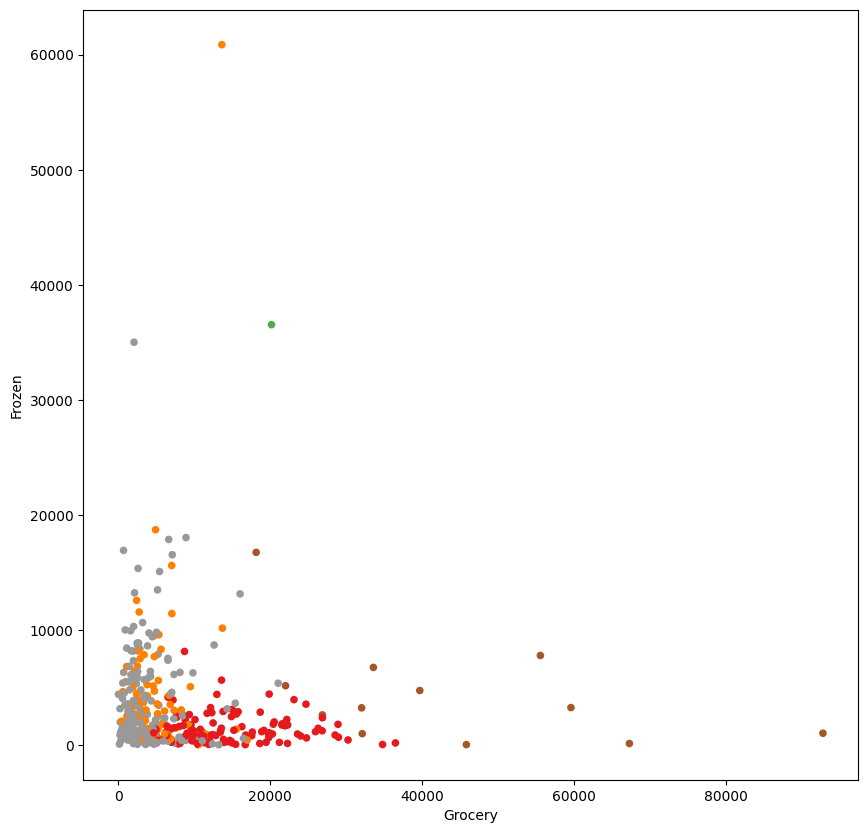

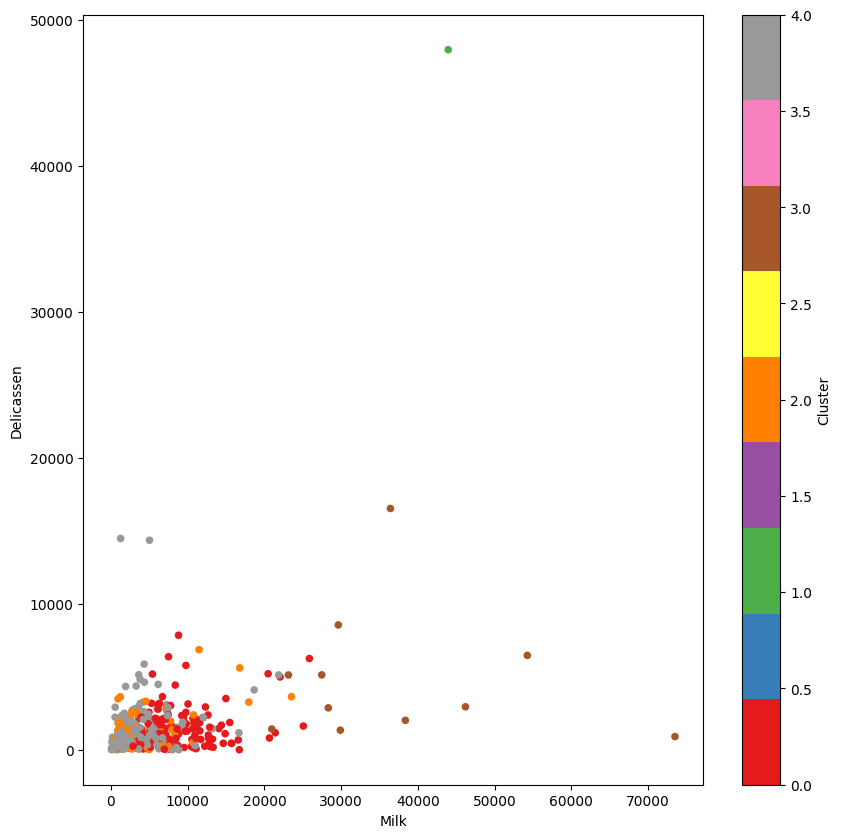

In [40]:
# 그래프로 표현 - 시각화
df.plot(kind='scatter', x='Grocery', y='Frozen', c='Cluster', cmap='Set1',
        colorbar=False, figsize=(10, 10))
df.plot(kind='scatter', x='Milk', y='Delicassen', c='Cluster', cmap='Set1',
        colorbar=True, figsize=(10, 10))
plt.show()
plt.close()

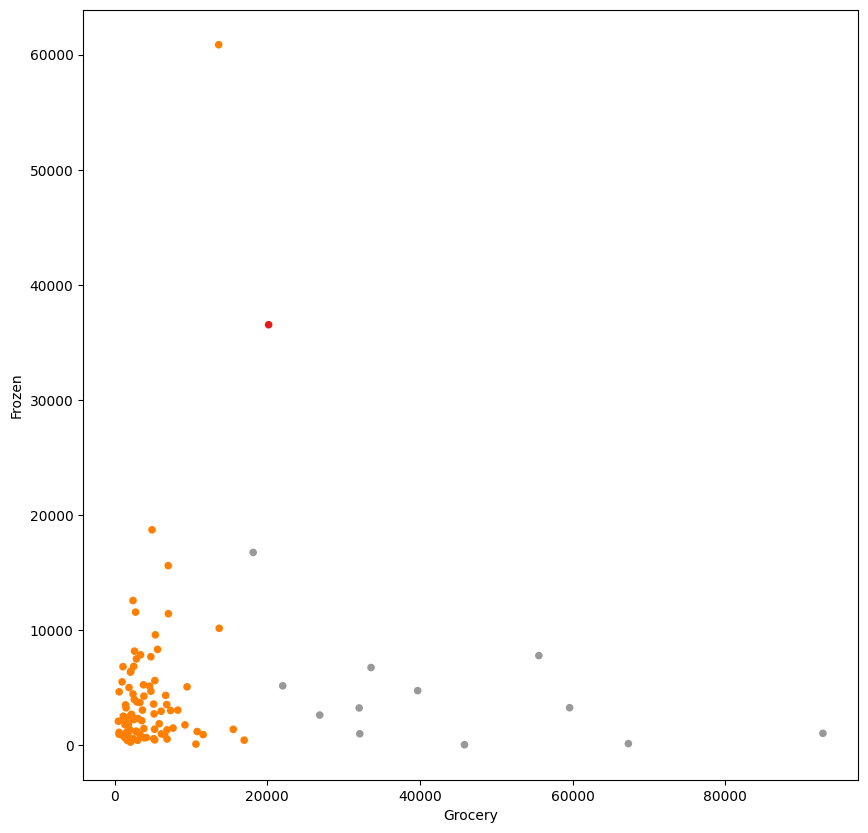

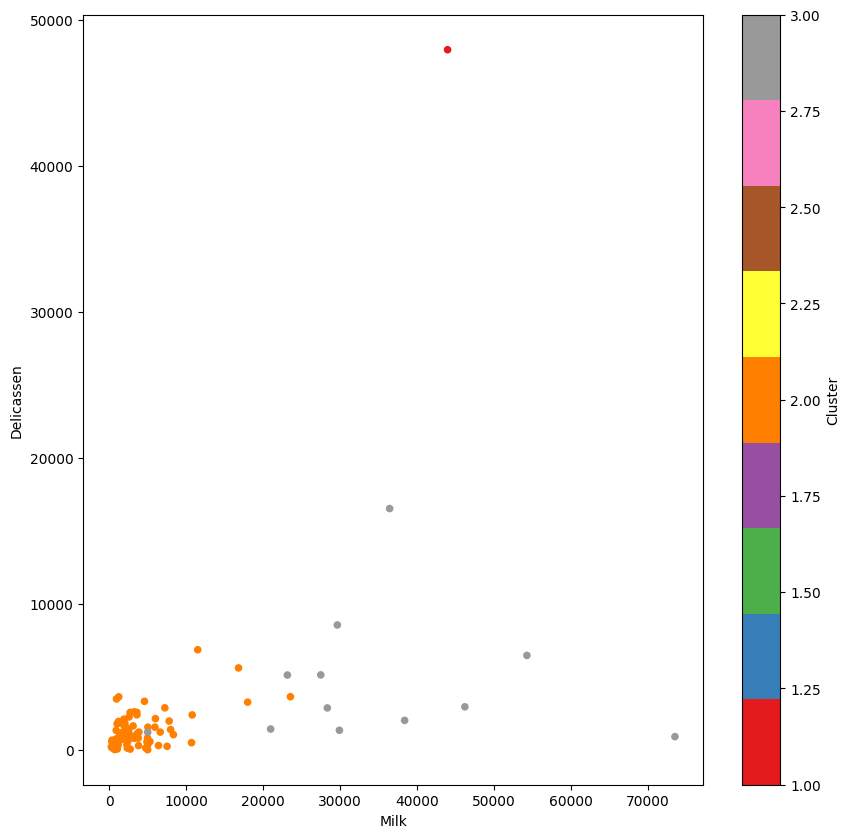

In [41]:
# 큰 값으로 구성된 클러스터(0, 4) 제외 - 값이 몰려 있는 구간을 자세하게 분석
mask = (df['Cluster'] == 0) | (df['Cluster'] == 4)
ndf = df[~mask]

ndf.plot(kind='scatter', x='Grocery', y='Frozen', c='Cluster', cmap='Set1',
         colorbar=False, figsize=(10, 10))
ndf.plot(kind='scatter', x='Milk', y='Delicassen', c='Cluster', cmap='Set1',
         colorbar=True, figsize=(10, 10))
plt.show()
plt.close()

### 4-2 DBSCAN

> Density-Based Spatial Clustering of Applications with Noise의 약자
>
- 데이터가 위치한 공간의 밀집도를 기준으로 클러스터를 구분

| 용어 | 정의 |
| --- | --- |
| **R (eps)** | 점을 중심으로 하는 반지름 |
| **M (min samples)** | 반지름 R 안에 들어와야 하는 점의 최소 개수 |
| **코어 포인트(core point)** | 자기를 중심으로 반지름 R의 공간에 최소 M개의 포인트가 존재하는 점 |
| **경계 포인트(border point)** | 코어 포인트는 아니지만 반지름 R 안에 다른 코어 포인트가 ****있는 점 |
| **Noise (outlier)** | 코어 포인트도 경계 포인트도 아닌 점 |
- 하나의 클러스터는 반지름 안에 서로 위치하는 모든 코어 포인트를 포함하는 방식으로 구성
- 밀집한 데이터끼리 하나의 클러스터 구성
    - 어느 클러스터에도 속하지 않는 점은 Noise로 남음
- 클러스터 개수를 미리 정하지 않음

#### 4-2-1 데이터 준비
- `pd.set_option("옵션이름", 값)`: 출력 설정
    
    
    | 옵션 | 의미 |
    | --- | --- |
    | `display.width` | 출력 화면의 너비 (`None`은 제한 없음) |
    | `display.max_rows` | 출력할 행의 개수 한도 |
    | `display.max_columns` | 출력할 열의 개수 한도 |
    | `display.max_colwidth` | 출력할 열의 너비 |
    | `display.unicode.east_asian_width` | 한글 등 동아시아 문자 폭을 맞춰 정렬 (`True`) |
- `folium.Map(location=[위도, 경도], tiles="지도스타일", zoom_start=정수)`: 지도 객체를 생성
    - `location`: 지도의 중심 좌표
    - `tiles`: 지도 스타일
    - `zoom_start`: 처음 확대 수준
- `folium.CircleMarker([위도, 경도], radius=반지름, color="테두리색", fill=True, fill_color="채움색", fill_opacity=투명도, popup=표시할텍스트).add_to(지도객체)`: 지도에 원형 마커를 추가
    - `popup`: 마커를 클릭했을 때 그 텍스트가 팝업으로 표시
- `지도객체.save("저장위치/파일이름.html")`: 지도 객체는 웹 페이지로 구현되므로, 스파이더(IDE) 등에서 확인하려면 HTML 파일로 저장해야 함
- `preprocessing.LabelEncoder()`: 문자열 같은 범주형 값을 0부터 시작하는 정수로 바꾸는 변환기 객체를 생성
- `변환기객체.fit_transform(시리즈)`: 값의 종류를 학습한 뒤 정수로 변환해 배열로 반환
- `preprocessing.OneHotEncoder()`: 원핫인코딩 변환기 객체를 생성

In [43]:
# -*- coding: utf-8 -*-

### 기본 라이브러리 불러오기
import pandas as pd
import folium

'''
[Step 1] 데이터 준비/기본 설정
'''

# 서울시내 중학교 진학률 데이터셋
# 구글 드라이브 마운트 (최초 1회 인증 진행)
from google.colab import drive
drive.mount('/content/drive')

# 데이터셋 가져오기
file_path = '/content/drive/MyDrive/학회/part 7 data/middle_shcool_graduates_report.xlsx'
df = pd.read_excel(file_path, header=0)

# IPython Console 디스플레이 옵션 설정하기
pd.set_option('display.width', None)                  # 출력 화면의 너비
pd.set_option('display.max_rows', 100)                # 출력할 행의 개수 한도
pd.set_option('display.max_columns', 10)              # 출력할 열의 개수 한도
pd.set_option('display.max_colwidth', 20)             # 출력할 열의 너비
pd.set_option('display.unicode.east_asian_width', True)   # 유니코드 사용 너비 조정

# 열 이름 배열 출력
print(df.columns.values)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['지역' '학교명' '코드' '유형' '주야' '남학생수' '여학생수' '일반고' '특성화고' '과학고' '외고_국제고'
 '예고_체고' '마이스터고' '자사고' '자공고' '기타진학' '취업' '미상' '위도' '경도']


In [44]:
'''
[Step 2] 데이터 탐색
'''

# 데이터 살펴보기
print(df.head())
print('\n')

# 데이터 자료형 확인
print(df.info())
print('\n')

# 데이터 통계 요약 정보 확인
print(df.describe())

     지역                               학교명  코드  유형  주야  ...  \
0  성북구  서울대학교사범대학부설중학교.....       3  국립  주간  ...   
1  종로구  서울대학교사범대학부설여자중학교...     3  국립  주간  ...   
2  강남구           개원중학교                     3  공립  주간  ...   
3  강남구           개포중학교                     3  공립  주간  ...   
4  서초구           경원중학교                     3  공립  주간  ...   

   기타진학  취업   미상       위도        경도  
0     0.004     0  0.000  37.594942  127.038909  
1     0.031     0  0.000  37.577473  127.003857  
2     0.009     0  0.003  37.491637  127.071744  
3     0.019     0  0.000  37.480439  127.062201  
4     0.010     0  0.000  37.510750  127.008900  

[5 rows x 20 columns]


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 415 entries, 0 to 414
Data columns (total 20 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   지역      415 non-null    object 
 1   학교명     415 non-null    object 
 2   코드      415 non-null    int64  
 3   유형      415 non-null    object 
 4   주야     

In [53]:
# 지도에 위치 표시
mschool_map = folium.Map(location=[37.55,126.98], tiles='CartoDB positron',
                         zoom_start=12)

# 중학교 위치 정보를 CircleMarker로 표시
for name, lat, lng in zip(df.학교명, df.위도, df.경도):
    folium.CircleMarker([lat, lng],
                        radius=5,                # 원의 반지름
                        color='brown',           # 원의 둘레 색상
                        fill=True,
                        fill_color='coral',      # 원을 채우는 색
                        fill_opacity=0.7,        # 투명도
                        popup=name
    ).add_to(mschool_map)

# 지도를 html 파일로 저장하기
mschool_map.save('./seoul_mschool_location.html')
mschool_map

In [54]:
'''
[Step 3] 데이터 전처리
'''

# 원핫인코딩(더미 변수)
from sklearn import preprocessing

label_encoder = preprocessing.LabelEncoder()           # label encoder 생성
onehot_encoder = preprocessing.OneHotEncoder()         # one hot encoder 생성

onehot_location = label_encoder.fit_transform(df['지역'])
onehot_code = label_encoder.fit_transform(df['코드'])
onehot_type = label_encoder.fit_transform(df['유형'])
onehot_day = label_encoder.fit_transform(df['주야'])

df['location'] = onehot_location
df['code'] = onehot_code
df['type'] = onehot_type
df['day'] = onehot_day

print(df.head())

     지역                               학교명  코드  유형  주야  ...  \
0  성북구  서울대학교사범대학부설중학교.....       3  국립  주간  ...   
1  종로구  서울대학교사범대학부설여자중학교...     3  국립  주간  ...   
2  강남구           개원중학교                     3  공립  주간  ...   
3  강남구           개포중학교                     3  공립  주간  ...   
4  서초구           경원중학교                     3  공립  주간  ...   

         경도  location  code  type  day  
0  127.038909        16     0     1    0  
1  127.003857        22     0     1    0  
2  127.071744         0     0     0    0  
3  127.062201         0     0     0    0  
4  127.008900        14     0     0    0  

[5 rows x 24 columns]


#### 4-2-2 모형 학습 및 검증

- `cluster.DBSCAN(eps=반경, min_samples=최소개수)`: DBSCAN 모형 객체를 생성
    - `eps`: 반지름 R
    - `min_samples`: 최소 포인트 개수 M
- `모형객체.labels_`: 클러스터 번호 배열
    - -1: Noise를 뜻함

In [55]:
'''
[Step 4] DBSCAN 군집 모형 - sklearn 사용
'''

# sklearn 라이브러리에서 cluster 군집 모형 가져오기
from sklearn import cluster

# 분석에 사용할 속성 선택(과학고, 외고국제고, 자사고 진학률)
columns_list = [9, 10, 13]
X = df.iloc[:, columns_list]
print(X[:5])
print('\n')

# 설명 변수 데이터 정규화
X = preprocessing.StandardScaler().fit(X).transform(X)

# DBSCAN 모형 객체 생성
dbm = cluster.DBSCAN(eps=0.2, min_samples=5)

# 모형 학습
dbm.fit(X)

# 예측(군집)
cluster_label = dbm.labels_
print(cluster_label)
print('\n')

# 예측 결과를 데이터프레임에 추가
df['Cluster'] = cluster_label
print(df.head())

   과학고  외고_국제고  자사고
0   0.018        0.007   0.227
1   0.000        0.035   0.043
2   0.009        0.012   0.090
3   0.013        0.013   0.065
4   0.007        0.010   0.282


[-1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1  0 -1 -1 -1 -1 -1 -1  2 -1  0 -1
 -1 -1 -1 -1  0 -1 -1 -1 -1 -1  0  3 -1 -1 -1 -1 -1 -1 -1  0 -1 -1  1  0
 -1 -1 -1  0 -1 -1 -1 -1  0 -1  0  0 -1 -1  0 -1 -1 -1  0  0 -1 -1  0 -1
 -1 -1  0 -1 -1 -1  0  2  0  0  0  0  0 -1 -1 -1  0 -1  0 -1 -1  0 -1  0
 -1  0  0 -1 -1 -1 -1  1  0 -1  0  0 -1 -1 -1  0 -1 -1 -1 -1 -1  0  1 -1
 -1  0  2  0 -1 -1  1 -1 -1 -1  0  0  0 -1 -1  0 -1 -1 -1  0  0 -1 -1 -1
 -1  0 -1 -1 -1  0 -1 -1 -1  0 -1  0  0 -1 -1 -1 -1 -1  0 -1  0  0 -1 -1
 -1 -1 -1  0 -1 -1 -1  1  0  3  1 -1  0  0 -1  0 -1 -1  0  0  2 -1 -1  3
  0  0 -1 -1 -1 -1  0 -1  0  0 -1  0  0  0 -1 -1  0 -1 -1 -1 -1 -1  2  0
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1  0 -1 -1 -1  0 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1  0 -1 -1 -1  0  0 -1 -1  0 -1  3  0  2 -1 -1
 -1 -1  0 -1 -1 -1  

In [59]:
# 클러스터 값으로 그룹화하고 그룹별 내용 출력(첫 5행만 출력)
grouped_cols = [0, 1, 3] + columns_list
grouped = df.groupby('Cluster')
for key, group in grouped:
    print('* key :', key)
    print('* number :', len(group))
    print(group.iloc[:, grouped_cols].head())
    print('\n')

# 그래프로 표현 - 시각화
colors = {-1:'gray', 0:'coral', 1:'blue', 2:'green', 3:'red', 4:'purple',
          5:'orange', 6:'brown', 7:'brick', 8:'yellow', 9:'magenta', 10:'cyan'}

# Stamen Terrain 대신 무료로 사용 가능한 'CartoDB positron' 타일을 적용하여 오류를 방지합니다.
cluster_map = folium.Map(location=[37.55,126.98], tiles='CartoDB positron',
                         zoom_start=12)

for name, lat, lng, clus in zip(df.학교명, df.위도, df.경도, df.Cluster):
    folium.CircleMarker([lat, lng],
                        radius=5,                      # 원의 반지름
                        color=colors[clus],            # 원의 둘레 색상
                        fill=True,
                        fill_color=colors[clus],       # 원을 채우는 색
                        fill_opacity=0.7,              # 투명도
                        popup=name
    ).add_to(cluster_map)

# 지도를 html 파일로 저장하기
cluster_map.save('./seoul_mschool_cluster.html')
cluster_map

* key : -1
* number : 255
     지역                               학교명  유형  과학고  외고_국제고  \
0  성북구  서울대학교사범대학부설중학교.....    국립   0.018        0.007   
1  종로구  서울대학교사범대학부설여자중학교...  국립   0.000        0.035   
2  강남구           개원중학교                  공립   0.009        0.012   
3  강남구           개포중학교                  공립   0.013        0.013   
4  서초구           경원중학교                  공립   0.007        0.010   

   자사고  
0   0.227  
1   0.043  
2   0.090  
3   0.065  
4   0.282  


* key : 0
* number : 102
      지역          학교명  유형  과학고  외고_국제고  자사고
13  서초구  동덕여자중학교  사립     0.0        0.022   0.038
22  강남구      수서중학교  공립     0.0        0.019   0.044
28  서초구      언남중학교  공립     0.0        0.015   0.050
34  강남구      은성중학교  사립     0.0        0.016   0.065
43  송파구      거원중학교  공립     0.0        0.021   0.054


* key : 1
* number : 45
         지역          학교명  유형  과학고  외고_국제고  자사고
46     강동구      동신중학교  사립     0.0          0.0   0.044
103    양천구      신원중학교  공립     0.0          0.0   0.006
118    구로구     

/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


In [62]:
# X2 데이터셋에 대하여 위의 과정을 반복(과학고, 외고국제고, 자사고 진학률 + 유형)
columns_list2 = [9, 10, 13, 22]
X2 = df.iloc[:, columns_list2]
print(X2[:5])
print('\n')

X2 = preprocessing.StandardScaler().fit(X2).transform(X2)
dbm2 = cluster.DBSCAN(eps=0.2, min_samples=5)
dbm2.fit(X2)
df['Cluster2'] = dbm2.labels_

grouped2_cols = [0, 1, 3] + columns_list2
grouped2 = df.groupby('Cluster2')
for key, group in grouped2:
    print('* key :', key)
    print('* number :', len(group))
    print(group.iloc[:, grouped2_cols].head())
    print('\n')

# 오류가 발생하는 'Stamen Terrain' 대신 'CartoDB positron' 타일 스타일을 적용합니다.
cluster2_map = folium.Map(location=[37.55,126.98], tiles='CartoDB positron',
                          zoom_start=12)

for name, lat, lng, clus in zip(df.학교명, df.위도, df.경도, df.Cluster2):
    folium.CircleMarker([lat, lng],
                        radius=5,                      # 원의 반지름
                        color=colors[clus],            # 원의 둘레 색상
                        fill=True,
                        fill_color=colors[clus],       # 원을 채우는 색
                        fill_opacity=0.7,              # 투명도
                        popup=name
    ).add_to(cluster2_map)

# 지도를 html 파일로 저장하기
cluster2_map.save('./seoul_mschool_cluster2.html')
cluster2_map

   과학고  외고_국제고  자사고  type
0   0.018        0.007   0.227     1
1   0.000        0.035   0.043     1
2   0.009        0.012   0.090     0
3   0.013        0.013   0.065     0
4   0.007        0.010   0.282     0


* key : -1
* number : 281
     지역                               학교명  유형  과학고  외고_국제고  \
0  성북구  서울대학교사범대학부설중학교.....    국립   0.018        0.007   
1  종로구  서울대학교사범대학부설여자중학교...  국립   0.000        0.035   
2  강남구           개원중학교                  공립   0.009        0.012   
3  강남구           개포중학교                  공립   0.013        0.013   
4  서초구           경원중학교                  공립   0.007        0.010   

   자사고  type  
0   0.227     1  
1   0.043     1  
2   0.090     0  
3   0.065     0  
4   0.282     0  


* key : 0
* number : 8
       지역      학교명  유형  과학고  외고_국제고  자사고  type
22   강남구  수서중학교  공립     0.0        0.019   0.044     0
43   송파구  거원중학교  공립     0.0        0.021   0.054     0
51   송파구  방이중학교  공립     0.0        0.021   0.068     0
93   강서구  방원중학교  공립     0.0        0.019 

/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


In [65]:
# X3 데이터셋에 대하여 위의 과정을 반복(과학고, 외고_국제고)
columns_list3 = [9, 10]
X3 = df.iloc[:, columns_list3]
print(X3[:5])
print('\n')

X3 = preprocessing.StandardScaler().fit(X3).transform(X3)
dbm3 = cluster.DBSCAN(eps=0.2, min_samples=5)
dbm3.fit(X3)
df['Cluster3'] = dbm3.labels_

grouped3_cols = [0, 1, 3] + columns_list3
grouped3 = df.groupby('Cluster3')
for key, group in grouped3:
    print('* key :', key)
    print('* number :', len(group))
    print(group.iloc[:, grouped3_cols].head())
    print('\n')

cluster3_map = folium.Map(location=[37.55,126.98], tiles='CartoDB positron',
                          zoom_start=12)

for name, lat, lng, clus in zip(df.학교명, df.위도, df.경도, df.Cluster3):
    folium.CircleMarker([lat, lng],
                        radius=5,                      # 원의 반지름
                        color=colors[clus],            # 원의 둘레 색상
                        fill=True,
                        fill_color=colors[clus],       # 원을 채우는 색
                        fill_opacity=0.7,              # 투명도
                        popup=name
    ).add_to(cluster3_map)

# 지도를 html 파일로 저장하기
cluster3_map.save('./seoul_mschool_cluster3.html')
cluster3_map

   과학고  외고_국제고
0   0.018        0.007
1   0.000        0.035
2   0.009        0.012
3   0.013        0.013
4   0.007        0.010


* key : -1
* number : 61
     지역                             학교명  유형  과학고  외고_국제고
0  성북구  서울대학교사범대학부설중학교.....  국립   0.018        0.007
3  강남구           개포중학교                공립   0.013        0.013
6  강남구         압구정중학교                공립   0.015        0.036
7  강남구  단국대학교사범대학부속중학교.....  사립   0.032        0.005
8  강남구           대명중학교                공립   0.013        0.029


* key : 0
* number : 160
      지역                               학교명  유형  과학고  외고_국제고
1   종로구  서울대학교사범대학부설여자중학교...  국립     0.0        0.035
13  서초구       동덕여자중학교                  사립     0.0        0.022
22  강남구           수서중학교                  공립     0.0        0.019
28  서초구           언남중학교                  공립     0.0        0.015
29  강남구           언북중학교                  공립     0.0        0.007


* key : 1
* number : 111
      지역      학교명  유형  과학고  외고_국제고
2   강남구  개원중학교  공립   0.009        

/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore
